# Real Estate Housing Price Prediction (Ridge & Lasso Regression)
**Task 2 - continuous regression modeling, feature engineering and residual error analysis**

**Goal:** predict `median_house_value` on the California Housing dataset, engineer interaction features, impute missing values,
handle multicollinearity, and compare **OLS**, **Ridge (L2)** and **Lasso (L1)** on **RMSE, MAE and R²**.

| Step in the brief | Section |
|---|---|
| 1. Load California Housing dataset | §1 |
| 2. Impute nulls, correlation heatmaps | §2 |
| 3. Standardize continuous variables, encode categoricals | §4 (+ feature engineering §3) |
| 4. Ridge & Lasso across many alphas with `GridSearchCV` | §5 |
| 5. Predicted vs actual, residual distribution curves | §7, §8 |
| Handle multicollinearity | §3 (VIF) |

**Dataset:** [housing.csv](https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv) ·
**Docs:** [Linear models](https://scikit-learn.org/stable/modules/linear_model.html) ·
[GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) ·
[Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures

warnings.filterwarnings("ignore", category=UserWarning)   # Lasso convergence chatter
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED, TARGET, CAT = 42, "median_house_value", ["ocean_proximity"]
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

## 1. Load the dataset

In [2]:
df = pd.read_csv(URL)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


## 2. Missing values, target and correlation heatmap
`total_bedrooms` has nulls. They are **imputed later inside the modelling Pipeline** (median learnt from the training split only), which avoids leaking test-set information.

In [4]:
nulls = df.isna().sum()
print("Missing values:\n", nulls[nulls > 0].to_string())
capped = int((df[TARGET] >= 500001).sum())
print(f"\nCensored target rows (>= $500,001): {capped} ({capped/len(df):.1%})  <- affects residual plots later")
df.describe().T.round(2)

Missing values:
 total_bedrooms    207

Censored target rows (>= $500,001): 965 (4.7%)  <- affects residual plots later


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


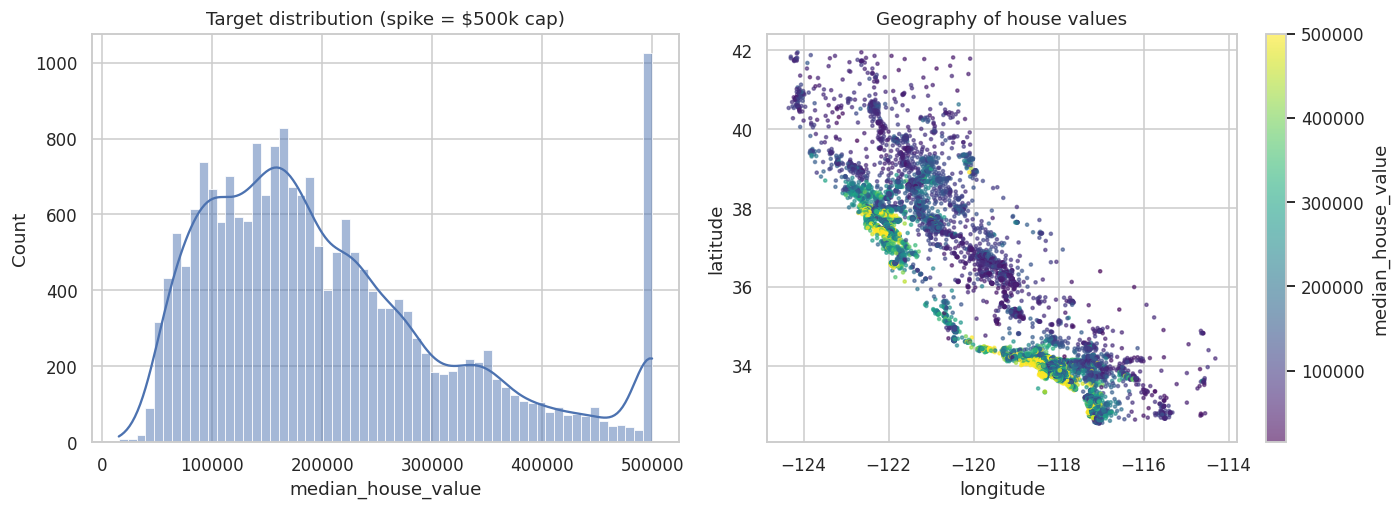

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(df[TARGET], bins=60, kde=True, ax=ax[0], color="#4c72b0")
ax[0].set(title="Target distribution (spike = $500k cap)")
sc = ax[1].scatter(df.longitude, df.latitude, c=df[TARGET], s=4, cmap="viridis", alpha=.6)
ax[1].set(title="Geography of house values", xlabel="longitude", ylabel="latitude")
plt.colorbar(sc, ax=ax[1], label=TARGET); plt.tight_layout(); plt.show()

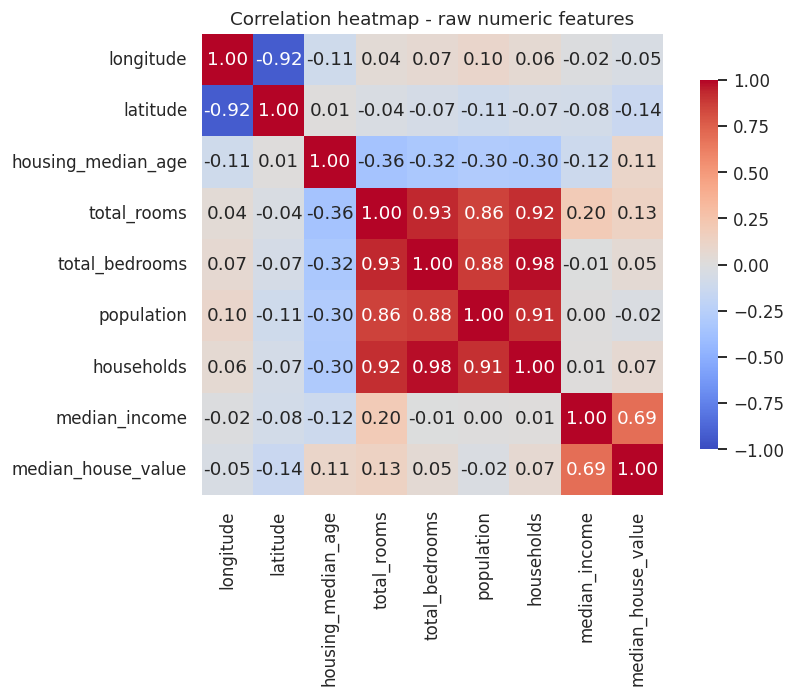

In [6]:
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap - raw numeric features"); plt.tight_layout(); plt.show()

**Reading the heatmap:** `total_rooms`, `total_bedrooms`, `population` and `households` are almost perfectly correlated with each other (they all just measure block size),
while `median_income` is the strongest single predictor of price. That is a multicollinearity problem, handled next.

## 3. Feature engineering and multicollinearity
* **Ratios** replace the raw count columns (rooms per household, people per household, bedroom share). They carry the useful signal without the size effect.
* Ratios are **log-transformed**: a few extreme blocks (up to 1,243 people per household) otherwise dominate OLS.
* **Interaction features** (domain-driven): `income × rooms`, `income × age`. Later, *all* pairwise interactions are tested too.
* **VIF** (variance inflation factor) quantifies multicollinearity; > 10 is a red flag.

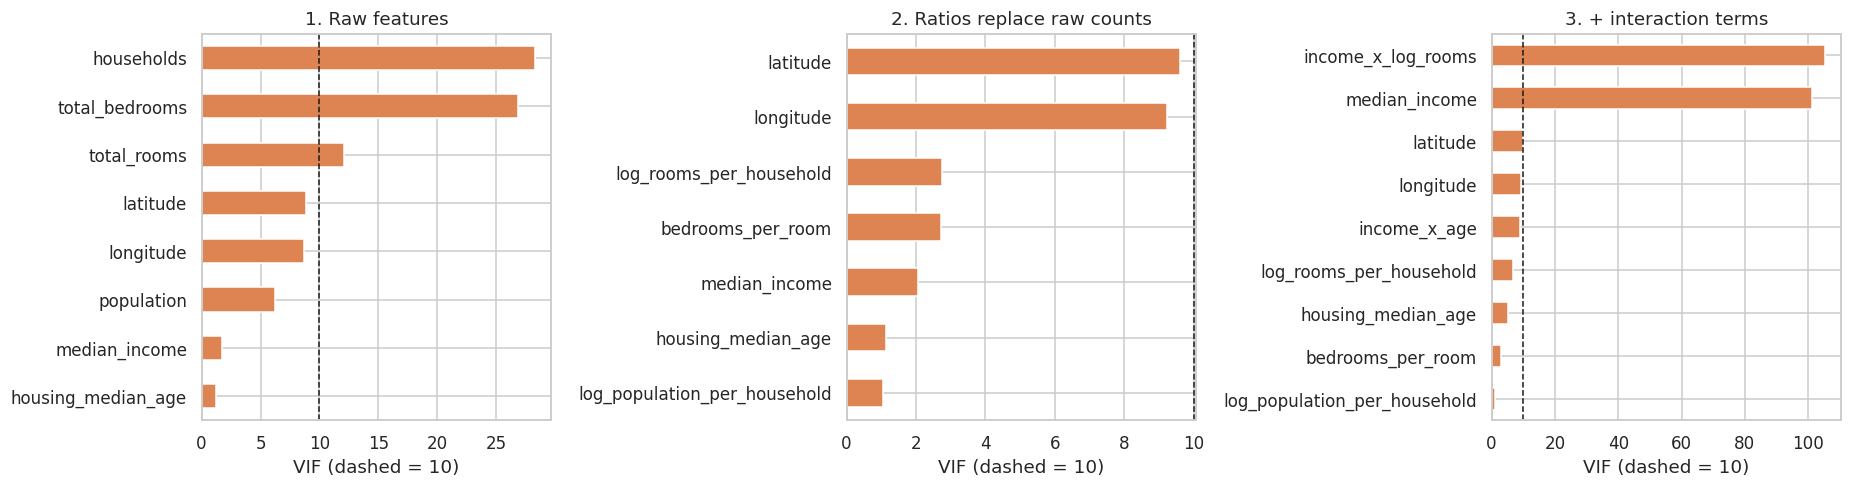

,1. Raw features,2. Ratios replace raw counts,3. + interaction terms
bedrooms_per_room,NaN,2.7,3.1
households,28.3,NaN,NaN
housing_median_age,1.3,1.1,5.3
income_x_age,NaN,NaN,8.9
income_x_log_rooms,NaN,NaN,105.2
latitude,8.8,9.6,9.8
log_population_per_household,NaN,1.0,1.1
log_rooms_per_household,NaN,2.8,6.7
longitude,8.7,9.2,9.4
median_income,1.7,2.1,101.0


In [7]:
RAW_COUNTS = ["total_rooms", "total_bedrooms", "population", "households"]

def engineer_features(d):
    """Row-wise only (learns nothing) -> safe before the split. NaNs are imputed later in the Pipeline."""
    o = d.copy()
    o["log_rooms_per_household"]      = np.log1p(o.total_rooms / o.households)
    o["log_population_per_household"] = np.log1p(o.population / o.households)
    o["bedrooms_per_room"]            = o.total_bedrooms / o.total_rooms
    o["income_x_log_rooms"]           = o.median_income * o.log_rooms_per_household   # interaction
    o["income_x_age"]                 = o.median_income * o.housing_median_age        # interaction
    return o

class Winsorizer(OneToOneFeatureMixin, BaseEstimator, TransformerMixin):
    """Clip each column to quantiles learnt on TRAINING data only."""
    def __init__(self, lower=0.005, upper=0.995): self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_, self.hi_ = np.nanquantile(X, self.lower, 0), np.nanquantile(X, self.upper, 0)
        self.n_features_in_ = X.shape[1]; return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)

def vif_table(X):
    X = (X - X.mean()) / X.std()
    return pd.Series({c: 1 / max(1e-12, 1 - LinearRegression().fit(X.drop(columns=c), X[c])
                                               .score(X.drop(columns=c), X[c])) for c in X.columns}
                     ).sort_values(ascending=False)

df_fe = engineer_features(df)
num = df_fe.drop(columns=[TARGET] + CAT); num = num.fillna(num.median())
inter = ["income_x_log_rooms", "income_x_age"]
stages = {
    "1. Raw features": vif_table(num[["longitude","latitude","housing_median_age","median_income"] + RAW_COUNTS]),
    "2. Ratios replace raw counts": vif_table(num[[c for c in num if c not in RAW_COUNTS + inter]]),
    "3. + interaction terms": vif_table(num[[c for c in num if c not in RAW_COUNTS]]),
}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (k, v) in zip(ax, stages.items()):
    v.sort_values().plot.barh(ax=a, color="#dd8452"); a.axvline(10, ls="--", c="k", lw=1)
    a.set(title=k, xlabel="VIF (dashed = 10)")
plt.tight_layout(); plt.show()
pd.DataFrame(stages).round(1)

**Takeaways**
* Raw counts: `households` (28) and `total_bedrooms` (27) are severely collinear. Replacing them with ratios removes the problem.
* Adding product terms re-introduces collinearity (a product correlates with its own parents; VIF ≈ 100). This is the expected price of interactions and exactly why **Ridge/Lasso** are compared below.
* Latitude/longitude stay near 9-10 because they are geographically correlated; both are kept since location is essential for house prices.

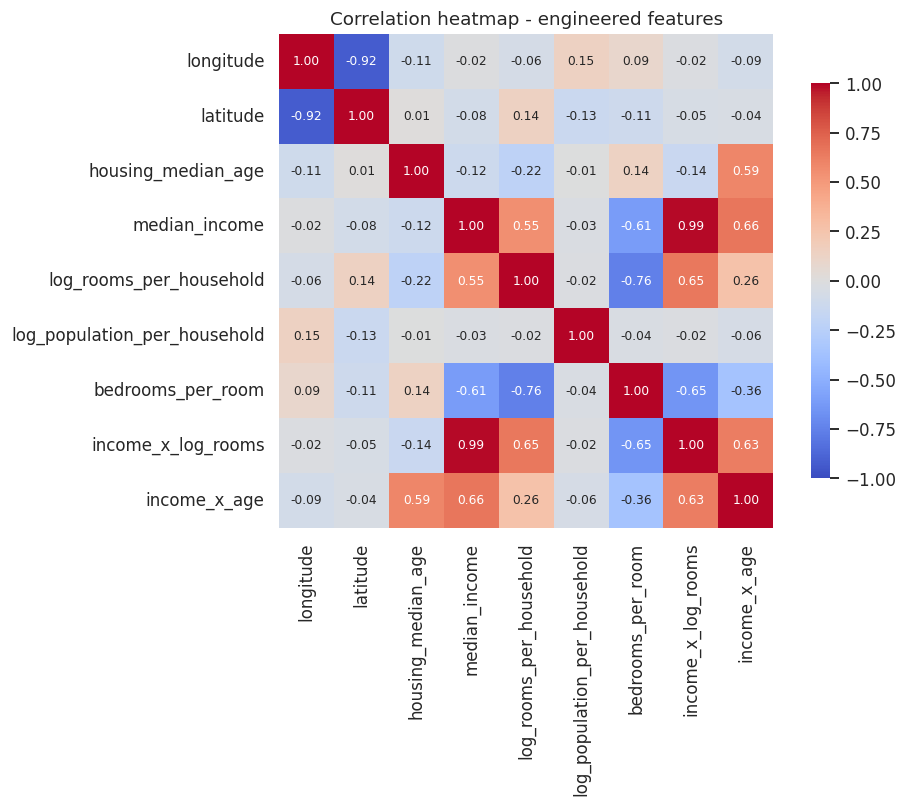

In [8]:
cols = [c for c in num if c not in RAW_COUNTS]
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(num[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            annot_kws={"size": 8}, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap - engineered features"); plt.tight_layout(); plt.show()

## 4. Split, impute, standardize and encode
* 80/20 split, **stratified on income bands** so train and test have the same income mix.
* `ColumnTransformer`: numeric → median-impute → winsorize → `StandardScaler`; categorical `ocean_proximity` → `OneHotEncoder(drop="first")` (avoids the dummy-variable trap that would break OLS).
* Everything is inside a `Pipeline`, so cross-validation never sees validation-fold statistics.

In [9]:
num_cols = [c for c in df_fe.columns if c not in [TARGET] + CAT + RAW_COUNTS]
X, y = df_fe[num_cols + CAT], df_fe[TARGET]
strata = pd.cut(df_fe.median_income, [0, 1.5, 3, 4.5, 6, np.inf], labels=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=SEED, stratify=strata)
print("train", X_train.shape, "| test", X_test.shape)
print("numeric features:", num_cols)

def make_pipeline(model, interactions=False):
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("win", Winsorizer(.005, .995)),
                          ("sc",  StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT),
    ], verbose_feature_names_out=False)
    steps = [("prep", prep)]
    if interactions:   # every pairwise product of the (already scaled) features
        steps.append(("poly", PolynomialFeatures(2, interaction_only=True, include_bias=False)))
    return Pipeline(steps + [("model", model)])

baseline_rmse = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
print(f"\nBaseline (always predict the training mean): RMSE = ${baseline_rmse:,.0f}")

train (16512, 10) | test (4128, 10)
numeric features: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'log_rooms_per_household', 'log_population_per_household', 'bedrooms_per_room', 'income_x_log_rooms', 'income_x_age']

Baseline (always predict the training mean): RMSE = $114,165


## 5. Fit OLS, Ridge and Lasso (`GridSearchCV` over alpha)
Two feature sets are compared: **Engineered** (13 features) and **Engineered + all pairwise interactions** (91 features).
The scoring metric is 5-fold CV RMSE. In `Lasso` the objective uses the *raw dollar* target, which is why the useful alphas are numerically large.

In [10]:
grids = {"Ridge (L2)": np.logspace(-2, 5, 15), "Lasso (L1)": np.logspace(-1, 4, 11)}
cv = KFold(5, shuffle=True, random_state=SEED)
feature_sets = {"Engineered": False, "Engineered + interactions": True}

fitted, searches = {}, {}
for fs, inter in feature_sets.items():
    fitted[(fs, "OLS")] = make_pipeline(LinearRegression(), inter).fit(X_train, y_train)
    for name, model in (("Ridge (L2)", Ridge(random_state=SEED)),
                        ("Lasso (L1)", Lasso(max_iter=3000, tol=1e-2, random_state=SEED))):
        gs = GridSearchCV(make_pipeline(model, inter), {"model__alpha": grids[name]},
                          scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1).fit(X_train, y_train)
        fitted[(fs, name)], searches[(fs, name)] = gs.best_estimator_, gs
        a = gs.best_params_["model__alpha"]
        edge = "  <-- at grid edge, widen grid!" if a in (grids[name][0], grids[name][-1]) else ""
        print(f"{fs:27s} {name:11s} best alpha = {a:>9.3f}   CV RMSE = ${-gs.best_score_:,.0f}{edge}")

Engineered                  Ridge (L2)  best alpha =    10.000   CV RMSE = $65,008


Engineered                  Lasso (L1)  best alpha =    31.623   CV RMSE = $65,010


Engineered + interactions   Ridge (L2)  best alpha =     0.316   CV RMSE = $59,385


Engineered + interactions   Lasso (L1)  best alpha =     3.162   CV RMSE = $59,347


### 5a. Alpha search curves
A U-shaped curve with the optimum *inside* the grid confirms the search range was wide enough.

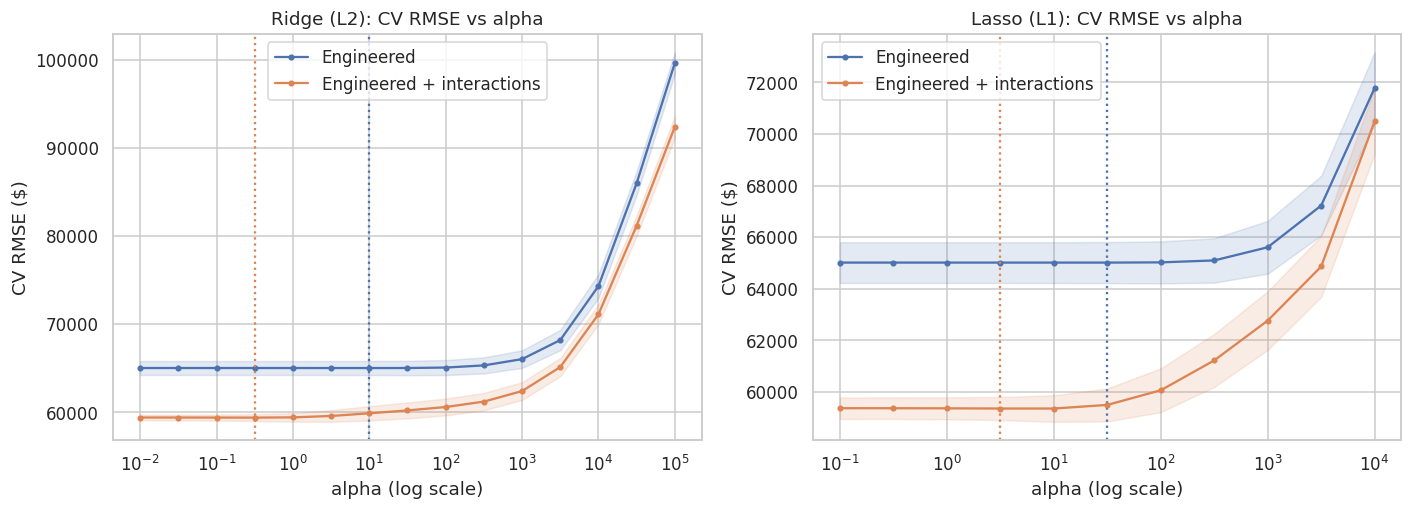

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, name in zip(axes, ("Ridge (L2)", "Lasso (L1)")):
    for fs, col in zip(feature_sets, ("#4c72b0", "#dd8452")):
        gs = searches[(fs, name)]
        a = gs.cv_results_["param_model__alpha"].astype(float)
        m, s = -gs.cv_results_["mean_test_score"], gs.cv_results_["std_test_score"]
        ax.plot(a, m, "-o", ms=3, c=col, label=fs); ax.fill_between(a, m-s, m+s, alpha=.15, color=col)
        ax.axvline(gs.best_params_["model__alpha"], c=col, ls=":")
    ax.set(xscale="log", title=f"{name}: CV RMSE vs alpha", xlabel="alpha (log scale)", ylabel="CV RMSE ($)"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Model comparison: RMSE, MAE, R²

In [12]:
rows = []
for (fs, name), m in fitted.items():
    p = m.predict(X_test); est = m.named_steps["model"]
    if (fs, name) in searches:
        gs = searches[(fs, name)]; i = gs.best_index_
        cvm, cvs = -gs.cv_results_["mean_test_score"][i], gs.cv_results_["std_test_score"][i]
    else:
        s = -cross_val_score(m, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"); cvm, cvs = s.mean(), s.std()
    rows.append({"Feature set": fs, "Model": name,
                 "RMSE ($)": np.sqrt(mean_squared_error(y_test, p)), "MAE ($)": mean_absolute_error(y_test, p),
                 "R²": r2_score(y_test, p), "CV RMSE mean": cvm, "CV RMSE std": cvs,
                 "alpha": getattr(est, "alpha", np.nan), "features": len(est.coef_),
                 "zeroed by Lasso": int((est.coef_ == 0).sum()) if name.startswith("Lasso") else np.nan})
results = pd.DataFrame(rows).set_index(["Feature set", "Model"])
results.style.format({"RMSE ($)": "{:,.0f}", "MAE ($)": "{:,.0f}", "R²": "{:.3f}", "CV RMSE mean": "{:,.0f}",
                      "CV RMSE std": "{:,.0f}", "alpha": "{:.3f}"}, na_rep="-")\
       .highlight_min(subset=["RMSE ($)", "MAE ($)"], color="#c7e9c0").highlight_max(subset=["R²"], color="#c7e9c0")

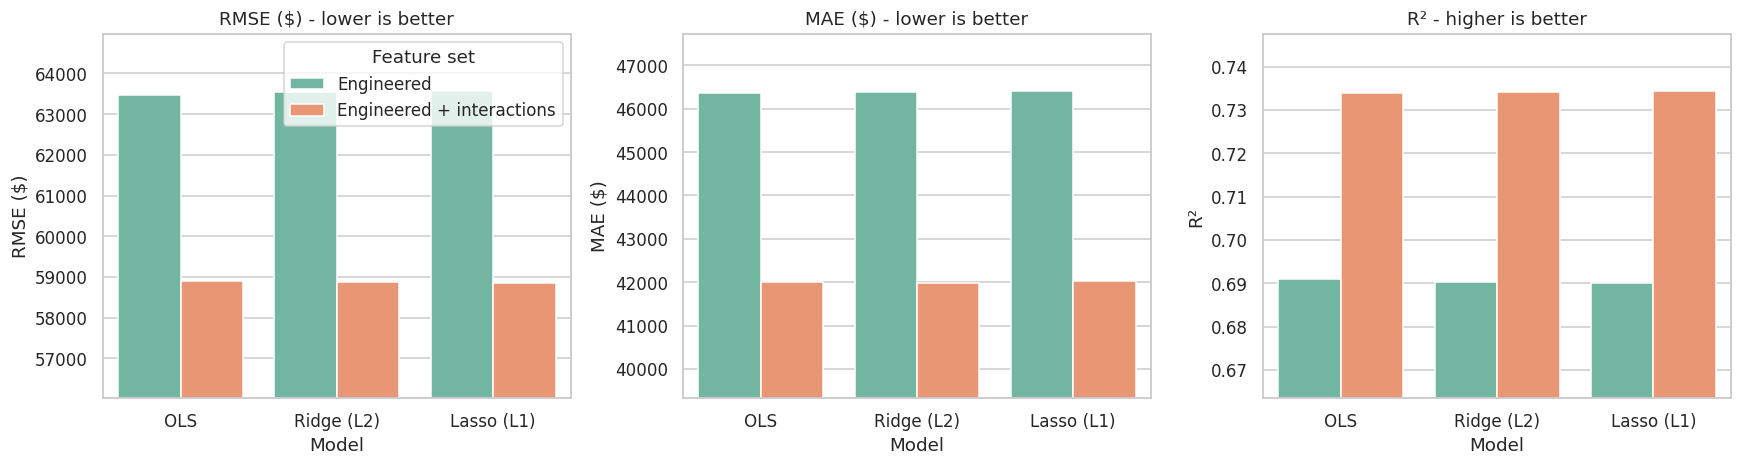

Baseline (mean predictor) RMSE: $114,165


In [13]:
r = results.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, metric in zip(axes, ("RMSE ($)", "MAE ($)", "R²")):
    sns.barplot(data=r, x="Model", y=metric, hue="Feature set", ax=ax, palette="Set2")
    lo, hi = r[metric].min(), r[metric].max(); pad = (hi - lo) * .6 + 1e-9
    ax.set_ylim(lo - pad, hi + pad * .5); ax.set_title(metric + (" - lower is better" if metric != "R²" else " - higher is better"))
    if ax is not axes[0]: ax.get_legend().remove()
plt.tight_layout(); plt.show()
print(f"Baseline (mean predictor) RMSE: ${baseline_rmse:,.0f}")

## 7. Predicted vs actual

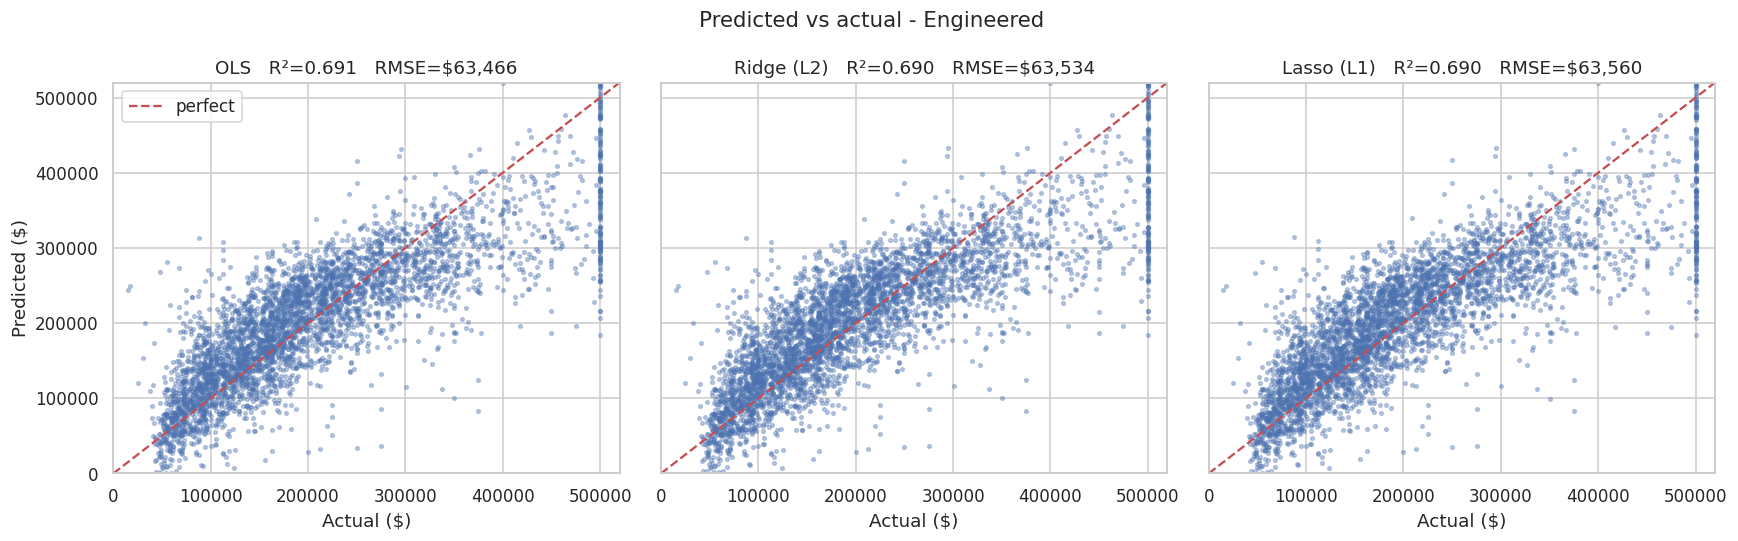

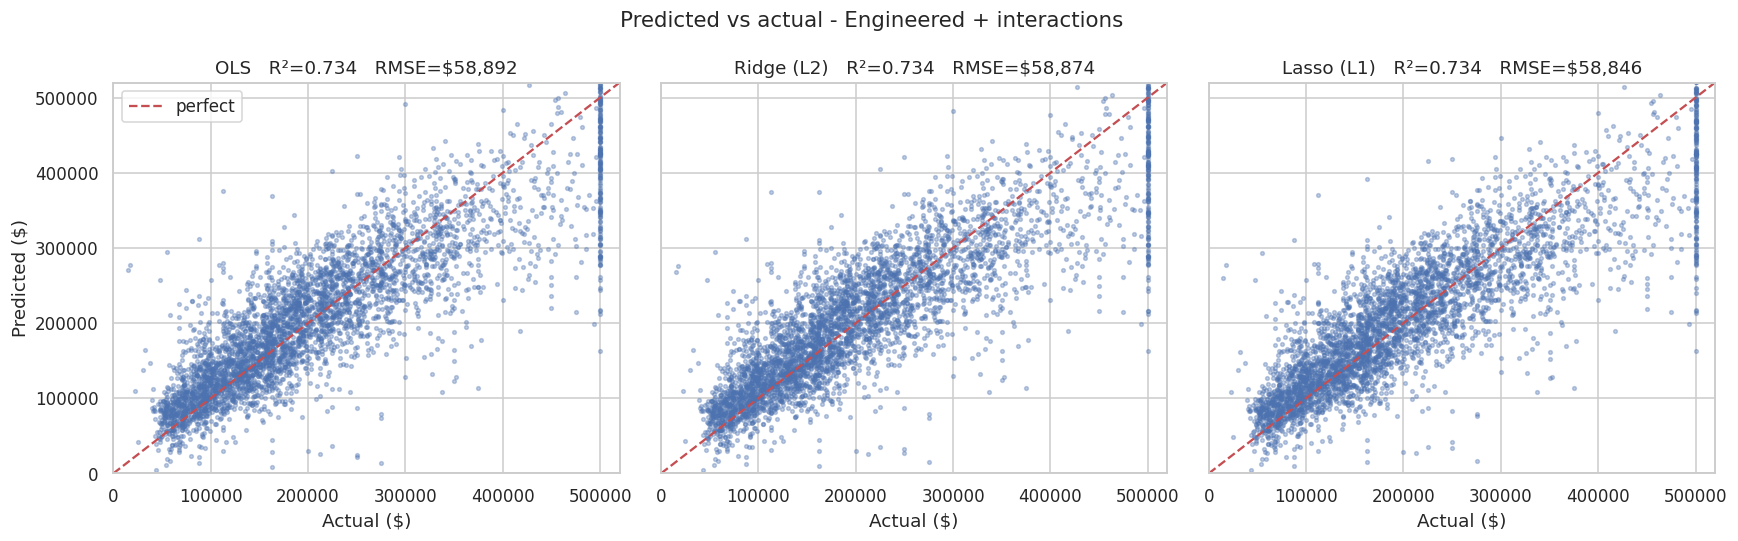

In [14]:
def pred_vs_actual(fs):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
    lim = [0, 5.2e5]
    for ax, name in zip(axes, ("OLS", "Ridge (L2)", "Lasso (L1)")):
        p = fitted[(fs, name)].predict(X_test)
        ax.scatter(y_test, p, s=6, alpha=.35, c="#4c72b0"); ax.plot(lim, lim, "r--", label="perfect")
        ax.set(title=f"{name}   R²={r2_score(y_test,p):.3f}   RMSE=${np.sqrt(mean_squared_error(y_test,p)):,.0f}",
               xlabel="Actual ($)", xlim=lim, ylim=lim)
    axes[0].set_ylabel("Predicted ($)"); axes[0].legend()
    plt.suptitle(f"Predicted vs actual - {fs}", fontsize=14); plt.tight_layout(); plt.show()

for fs in feature_sets: pred_vs_actual(fs)

## 8. Residual error analysis
Three views per model: the **residual distribution with KDE curve** (centered on 0? skewed?), a **Q-Q plot** (normality of errors) and **residuals vs fitted** (constant variance / missed structure).

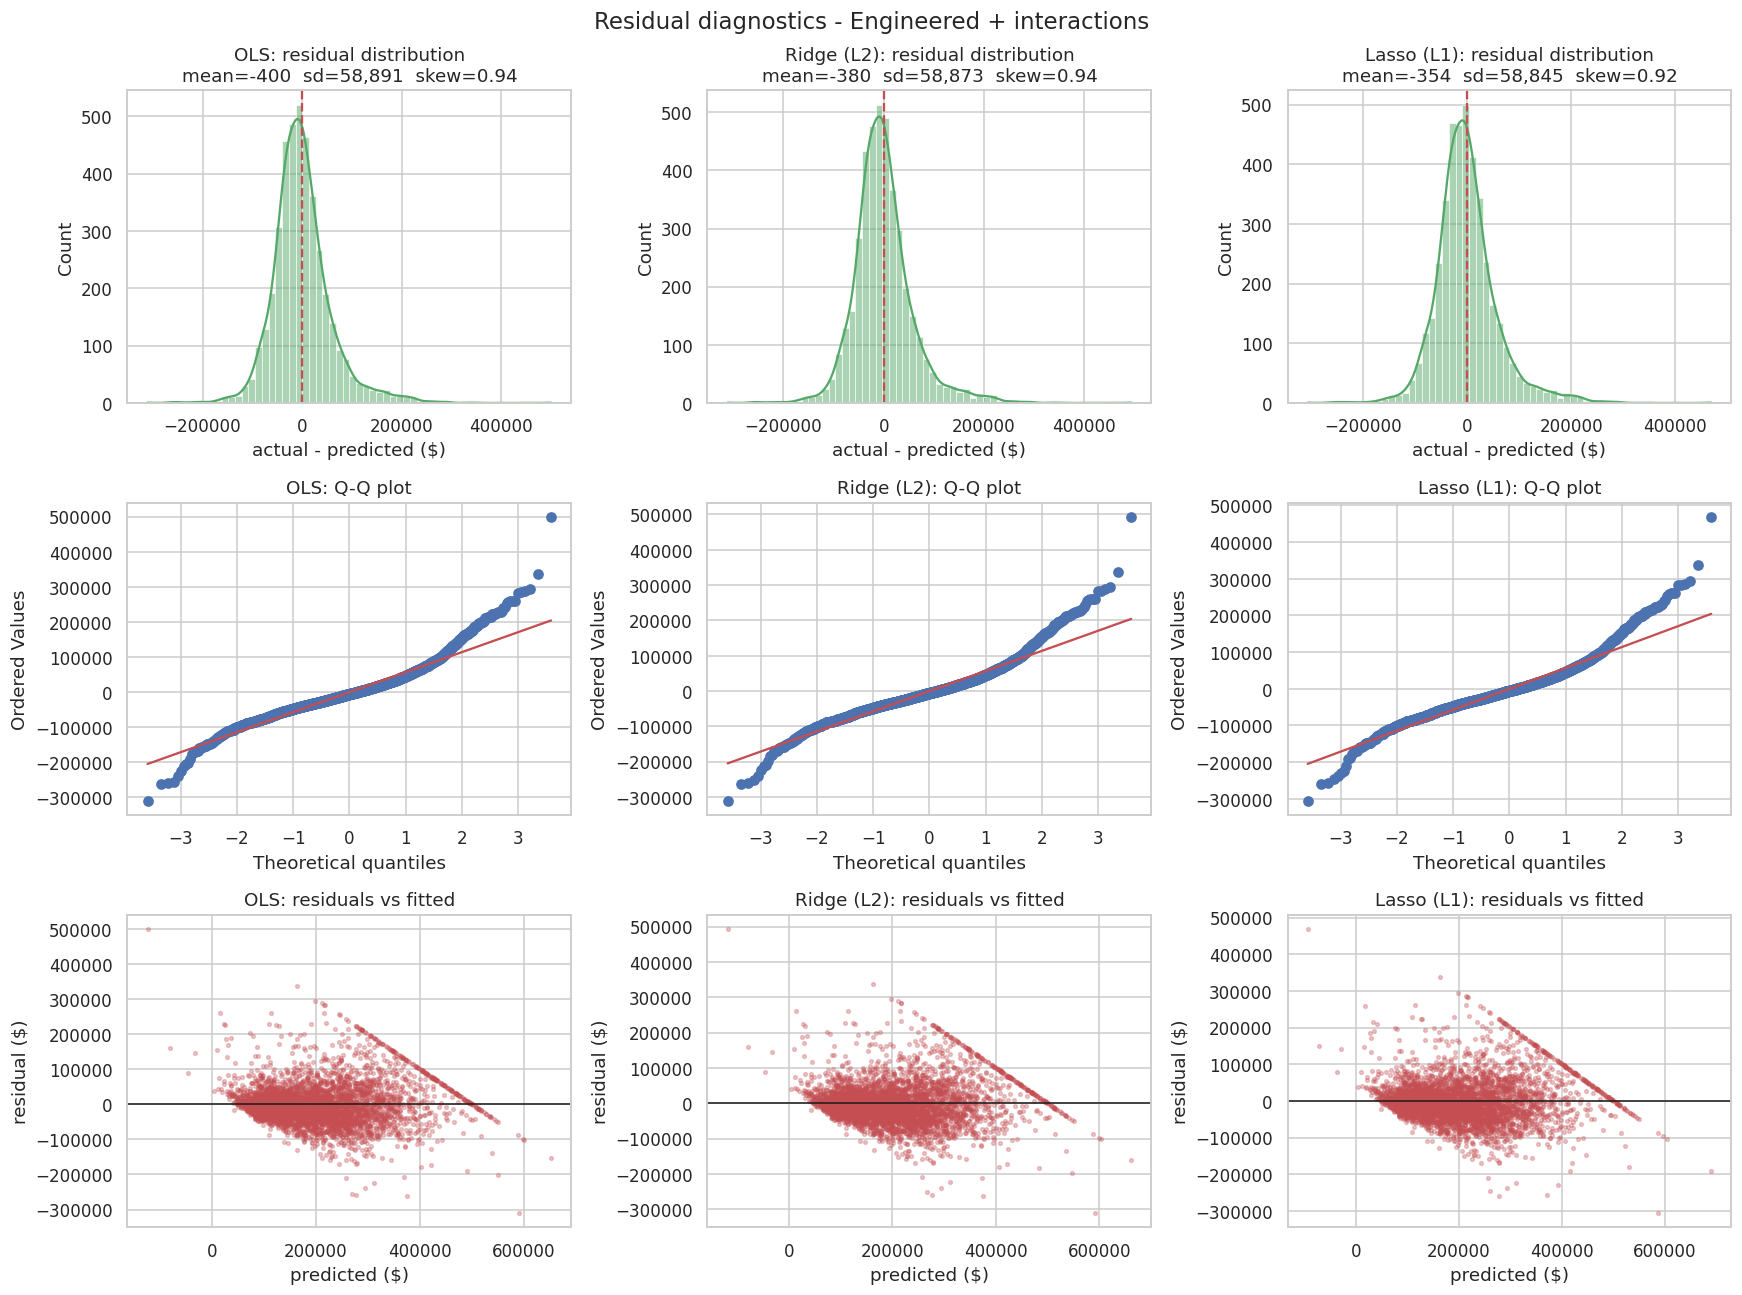

In [15]:
from scipy import stats

def residual_plots(fs):
    fig, axes = plt.subplots(3, 3, figsize=(16, 12))
    for j, name in enumerate(("OLS", "Ridge (L2)", "Lasso (L1)")):
        p = fitted[(fs, name)].predict(X_test); res = y_test.values - p
        sns.histplot(res, bins=60, kde=True, ax=axes[0, j], color="#55a868"); axes[0, j].axvline(0, c="r", ls="--")
        axes[0, j].set(title=f"{name}: residual distribution\nmean={res.mean():,.0f}  sd={res.std():,.0f}  skew={stats.skew(res):.2f}",
                       xlabel="actual - predicted ($)")
        stats.probplot(res, dist="norm", plot=axes[1, j]); axes[1, j].set_title(f"{name}: Q-Q plot")
        axes[2, j].scatter(p, res, s=6, alpha=.3, c="#c44e52"); axes[2, j].axhline(0, c="k", lw=1)
        axes[2, j].set(title=f"{name}: residuals vs fitted", xlabel="predicted ($)", ylabel="residual ($)")
    plt.suptitle(f"Residual diagnostics - {fs}", fontsize=15); plt.tight_layout(); plt.show()

residual_plots("Engineered + interactions")

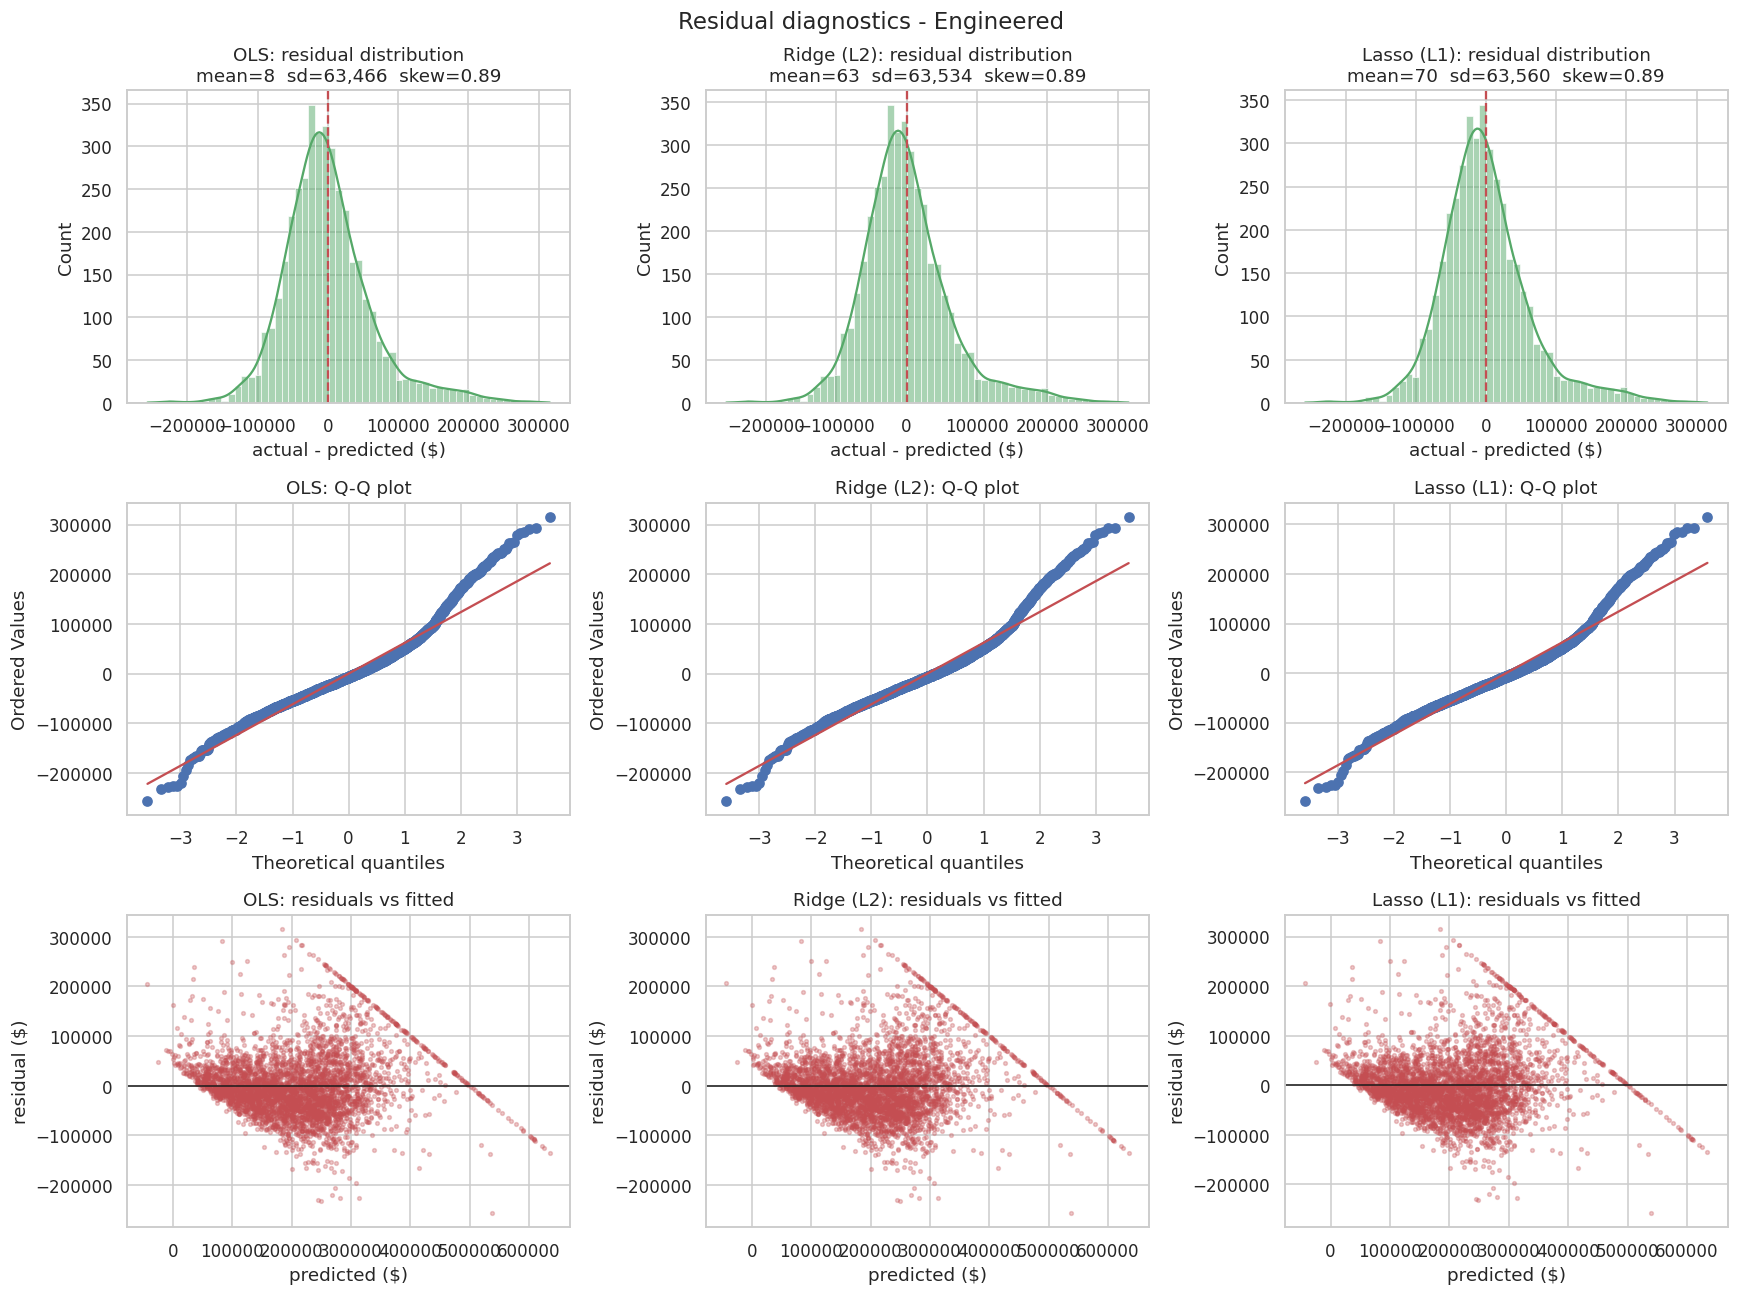

In [16]:
residual_plots('Engineered')

**Interpretation**
* Residuals are centered on ~0 with a **right skew** and heavy tails (Q-Q plots bend away from the line at both ends): the models under-predict very expensive blocks.
* The sharp **diagonal streak** in residuals-vs-fitted is not a bug: it is the censored $500,001 target. For those rows, `residual = 500,001 − prediction` is a straight line.
* The spread of residuals *appears* to change with the fitted value (visual impression only, not formally tested), so modelling `log(price)` is worth trying.
* The three models give nearly identical residual shapes, so the remaining error is **model-form (linearity) error, not variance**.

## 9. What did regularization do to the coefficients?

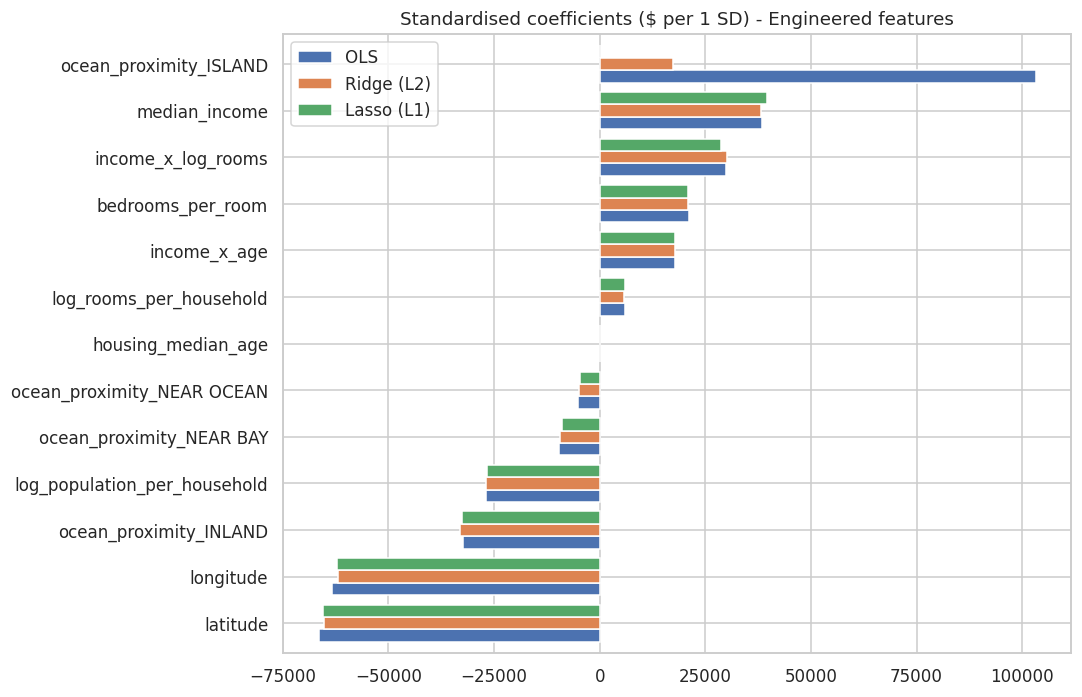

,OLS,Ridge (L2),Lasso (L1)
longitude,-63305.0,-62059.0,-62181.0
latitude,-66542.0,-65265.0,-65475.0
housing_median_age,-28.0,-12.0,27.0
median_income,38324.0,38157.0,39620.0
log_rooms_per_household,5998.0,5804.0,6000.0
log_population_per_household,-26839.0,-26816.0,-26769.0
bedrooms_per_room,21114.0,21006.0,21009.0
income_x_log_rooms,29910.0,30135.0,28642.0
income_x_age,17889.0,17911.0,17785.0
ocean_proximity_INLAND,-32472.0,-33035.0,-32632.0


In [17]:
fs = "Engineered"
names = fitted[(fs, "OLS")][:-1].get_feature_names_out()
coefs = pd.DataFrame({m: fitted[(fs, m)].named_steps["model"].coef_ for m in ("OLS", "Ridge (L2)", "Lasso (L1)")}, index=names)
coefs.sort_values("OLS").plot.barh(figsize=(10, 6.5), width=.8)
plt.title("Standardised coefficients ($ per 1 SD) - Engineered features"); plt.tight_layout(); plt.show()
coefs.round(0)

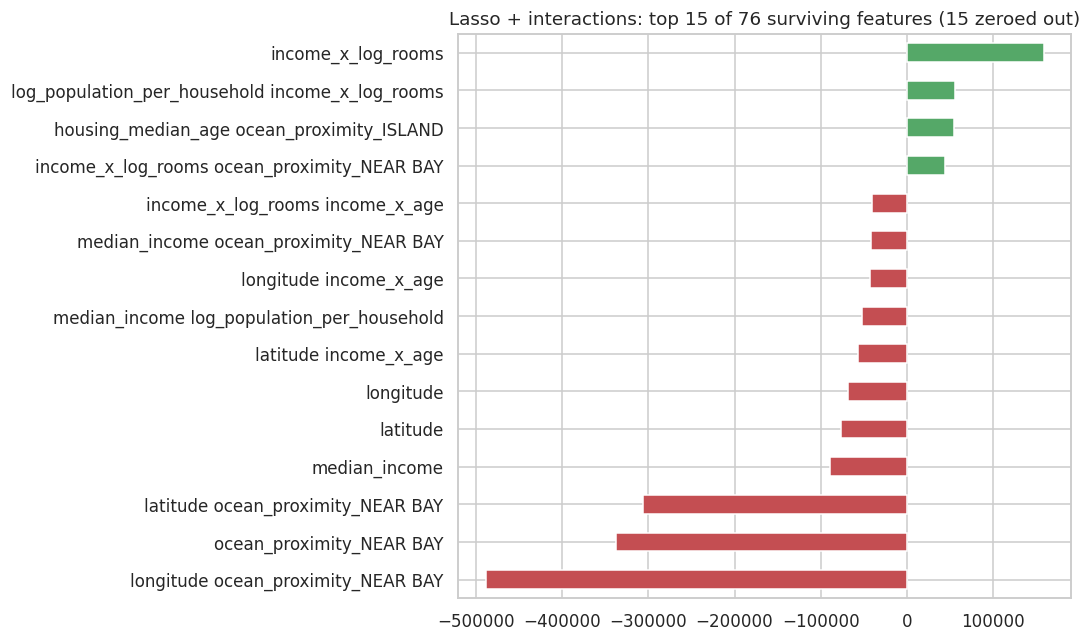

In [18]:
fs = "Engineered + interactions"
names = fitted[(fs, "Lasso (L1)")][:-1].get_feature_names_out()
c = pd.Series(fitted[(fs, "Lasso (L1)")].named_steps["model"].coef_, index=names)
kept = c[c != 0]; top = kept.reindex(kept.abs().sort_values(ascending=False).index).head(15).sort_values()
top.plot.barh(figsize=(10, 6), color=np.where(top > 0, "#55a868", "#c44e52"))
plt.title(f"Lasso + interactions: top 15 of {len(kept)} surviving features ({(c == 0).sum()} zeroed out)")
plt.tight_layout(); plt.show()

## 10. Conclusions

In [19]:
best = results["RMSE ($)"].idxmin()
b, w = results.loc[best], results.loc[("Engineered", "OLS")]
print(f"Best test RMSE : {best}  ->  ${b['RMSE ($)']:,.0f}  (MAE ${b['MAE ($)']:,.0f}, R² {b['R²']:.3f})")
print(f"Plain OLS on engineered features: ${w['RMSE ($)']:,.0f}   -> interactions improve RMSE by ${w['RMSE ($)'] - b['RMSE ($)']:,.0f} ({(w['RMSE ($)'] - b['RMSE ($)'])/w['RMSE ($)']:.1%})")
same = results.xs("Engineered + interactions")["RMSE ($)"]
print(f"Spread between OLS / Ridge / Lasso on the interaction set: ${same.max() - same.min():,.0f} RMSE "
      f"vs CV std ≈ ${results['CV RMSE std'].mean():,.0f}")

Best test RMSE : ('Engineered + interactions', 'Lasso (L1)')  ->  $58,846  (MAE $42,022, R² 0.734)
Plain OLS on engineered features: $63,466   -> interactions improve RMSE by $4,620 (7.3%)
Spread between OLS / Ridge / Lasso on the interaction set: $46 RMSE vs CV std ≈ $590


1. **Feature engineering matters most.** Pairwise interactions lower RMSE by roughly $4-5k (≈7%); all models crush the $114k mean-predictor baseline.
2. **Regularization changes accuracy very little here.** OLS, Ridge and Lasso land within about $50 of each other, which is far below the fold-to-fold noise. With ~16.5k training rows and ≤ 91 features, variance is not the bottleneck. *Don't claim a winner on the last decimal.*
3. **Lasso's real value is sparsity**: it matches OLS accuracy while zeroing ~15 of the 91 interaction features, giving a more compact model.
4. **Multicollinearity** was handled in two layers: ratios replace raw counts (VIF 28 → ~3), and Ridge/Lasso absorb the collinearity re-introduced by interaction terms.
5. **Limits:** residuals are skewed and heteroscedastic and the target is censored at $500k, so a linear model has a ceiling. Next steps: model `log(price)` via `TransformedTargetRegressor`, add `ElasticNet`, center interactions, and try gradient boosting.

*Data are 1990 census blocks, so use this for learning, not real valuation.*

In [20]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(fitted[best], "models/best_model.joblib")   # NOTE: pass inputs through engineer_features() first
results.round(4).to_csv("benchmark_results.csv")
print("saved models/best_model.joblib and benchmark_results.csv")

saved models/best_model.joblib and benchmark_results.csv
